In [2]:
!pip install yfinance -q

# Canadian Bank Performance and Risk Analysis

**Author:** Shyla Khullar  
**Tools:** Python, pandas, NumPy, yfinance, matplotlib, seaborn, SQLite

## Business Question

How have Canada’s largest publicly traded banks compared in historical return, volatility, downside risk, and risk-adjusted performance relative to a Canadian financial-sector benchmark?

> This project is an educational analysis of historical market data and is not investment advice.

In [4]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from datetime import datetime

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [5]:
tickers = ["RY.TO", "TD.TO", "BMO.TO", "BNS.TO", "CM.TO", "NA.TO", "XFN.TO"]

company_names = {
    "RY.TO": "Royal Bank",
    "TD.TO": "TD Bank",
    "BMO.TO": "Bank of Montreal",
    "BNS.TO": "Scotiabank",
    "CM.TO": "CIBC",
    "NA.TO": "National Bank",
    "XFN.TO": "XFN Benchmark"
}

start_date = "2020-01-01"
end_date = datetime.today().strftime("%Y-%m-%d")

raw_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

prices = raw_data["Close"].rename(columns=company_names).dropna(how="all")

print(f"Downloaded {prices.shape[0]} trading days.")
print(f"Period: {prices.index.min().date()} to {prices.index.max().date()}")
prices.head()

Downloaded 1731 trading days.
Period: 2020-01-02 to 2026-11-23


Ticker,Bank of Montreal,Scotiabank,CIBC,National Bank,Royal Bank,TD Bank,XFN Benchmark
Date,,,,,,,
2020-01-02,74.762909,50.154293,39.035156,55.743317,79.891563,54.432816,31.846720
2020-01-03,74.577599,50.106644,38.905315,55.790005,79.598381,54.388332,31.798616
2020-01-06,74.518288,49.920509,38.786289,55.696613,79.613808,54.395756,31.790609
2020-01-07,74.392258,49.451782,38.710556,55.852272,79.644669,54.336430,31.806644
2020-01-08,74.933449,49.899853,38.934166,55.992363,80.277328,54.759033,32.047050


In [6]:
quality_report = pd.DataFrame({
    "Missing Values": prices.isna().sum(),
    "Non-Positive Prices": (prices <= 0).sum(),
    "First Observation": prices.apply(
        lambda column: column.first_valid_index().date()
    ),
    "Last Observation": prices.apply(
        lambda column: column.last_valid_index().date()
    )
})

duplicate_dates = prices.index.duplicated().sum()

print(f"Duplicate dates: {duplicate_dates}")
display(quality_report)

# Keep complete, chronologically ordered observations
prices = (
    prices[~prices.index.duplicated(keep="first")]
    .sort_index()
    .dropna()
)

print(f"Clean dataset: {prices.shape[0]} rows and {prices.shape[1]} assets.")

Duplicate dates: 0


,Missing Values,Non-Positive Prices,First Observation,Last Observation
Ticker,,,,
Bank of Montreal,0,0,2020-01-02,2026-11-23
Scotiabank,0,0,2020-01-02,2026-11-23
CIBC,0,0,2020-01-02,2026-11-23
National Bank,0,0,2020-01-02,2026-11-23
Royal Bank,0,0,2020-01-02,2026-11-23
TD Bank,0,0,2020-01-02,2026-11-23
XFN Benchmark,0,0,2020-01-02,2026-11-23


Clean dataset: 1731 rows and 7 assets.


In [8]:
# Core financial calculations
trading_days = 252
risk_free_rate = 0.03  # Assumed annual risk-free rate of 3%

daily_returns = prices.pct_change().dropna()
wealth_index = prices / prices.iloc[0]
cumulative_returns = wealth_index - 1

annualized_return = (
    prices.iloc[-1] / prices.iloc[0]
) ** (trading_days / len(daily_returns)) - 1

annualized_volatility = daily_returns.std() * np.sqrt(trading_days)

sharpe_ratio = (
    (daily_returns.mean() - risk_free_rate / trading_days)
    / daily_returns.std()
    * np.sqrt(trading_days)
)

running_peak = wealth_index.cummax()
drawdowns = wealth_index / running_peak - 1
maximum_drawdown = drawdowns.min()

summary_metrics = pd.DataFrame({
    "Total Return": cumulative_returns.iloc[-1],
    "Annualized Return": annualized_return,
    "Annualized Volatility": annualized_volatility,
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": maximum_drawdown
}).sort_values("Sharpe Ratio", ascending=False)

display(
    summary_metrics.style.format({
        "Total Return": "{:.1%}",
        "Annualized Return": "{:.1%}",
        "Annualized Volatility": "{:.1%}",
        "Sharpe Ratio": "{:.2f}",
        "Maximum Drawdown": "{:.1%}"
    })
)

,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Ticker,,,,,
Royal Bank,238.3%,19.4%,19.8%,0.84,-33.8%
CIBC,288.1%,21.8%,23.1%,0.84,-38.9%
National Bank,263.5%,20.7%,24.6%,0.76,-48.2%
XFN Benchmark,186.8%,16.6%,19.3%,0.74,-39.9%
TD Bank,205.3%,17.7%,22.4%,0.70,-35.1%
Bank of Montreal,208.3%,17.8%,24.5%,0.67,-45.6%
Scotiabank,144.7%,13.9%,22.0%,0.57,-37.5%


## Initial Findings

- **CIBC generated the strongest absolute performance**, with a 288.1% total return and a 21.8% annualized return.
- **Royal Bank displayed the strongest overall risk-return profile.** Its 0.84 Sharpe ratio matched CIBC’s, while its volatility and maximum drawdown were lower.
- **National Bank produced strong returns but experienced the deepest drawdown**, falling 48.2% from a previous peak.
- **Scotiabank underperformed the XFN benchmark** in total return, annualized return, and risk-adjusted performance.
- Every individual bank experienced substantial downside risk, demonstrating why return should not be evaluated without volatility and drawdown.

These findings describe the selected historical period and do not imply future performance.

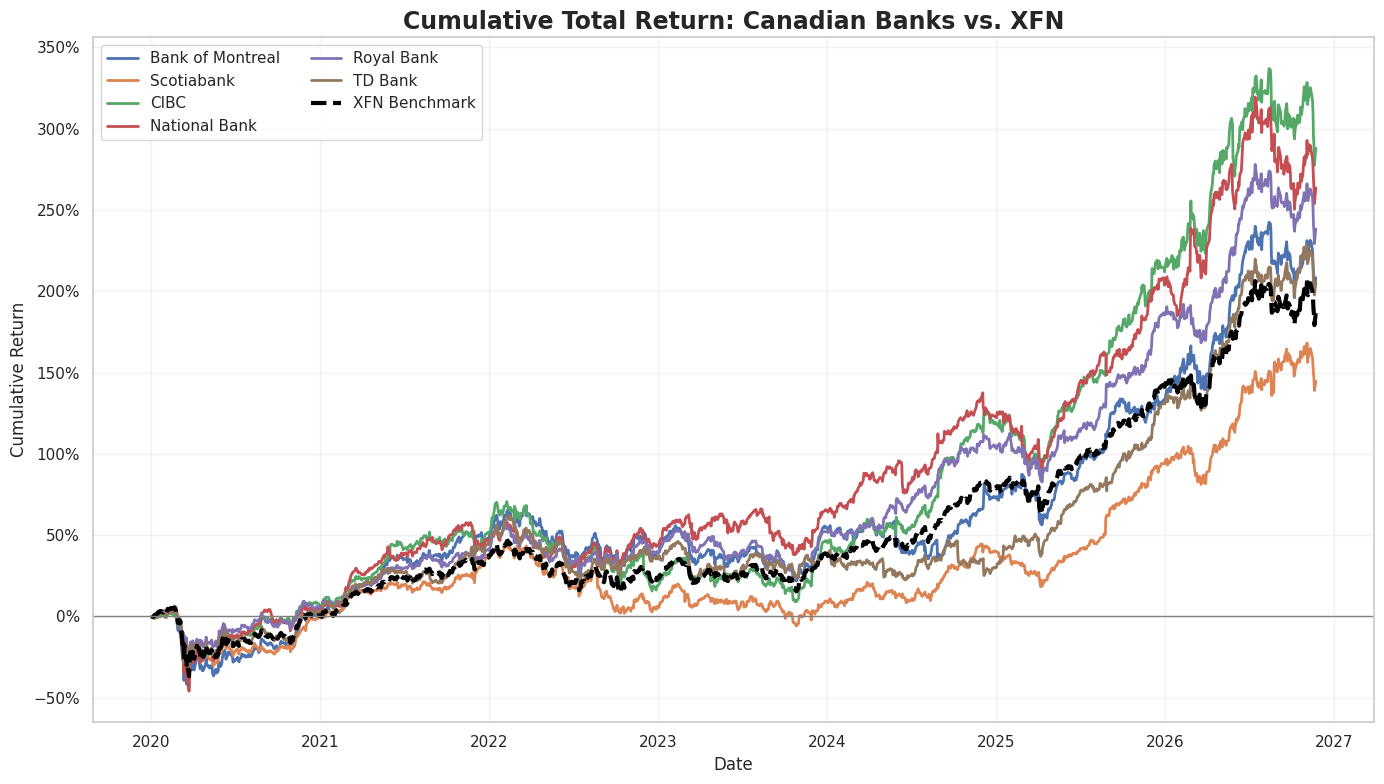

In [9]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(14, 8))

for asset in cumulative_returns.columns:
    if asset == "XFN Benchmark":
        ax.plot(
            cumulative_returns.index,
            cumulative_returns[asset],
            label=asset,
            color="black",
            linewidth=3,
            linestyle="--"
        )
    else:
        ax.plot(
            cumulative_returns.index,
            cumulative_returns[asset],
            label=asset,
            linewidth=2
        )

ax.axhline(0, color="gray", linewidth=1)
ax.set_title(
    "Cumulative Total Return: Canadian Banks vs. XFN",
    fontsize=17,
    fontweight="bold"
)
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(ncol=2, frameon=True)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("cumulative_returns.png", dpi=300, bbox_inches="tight")
plt.show()

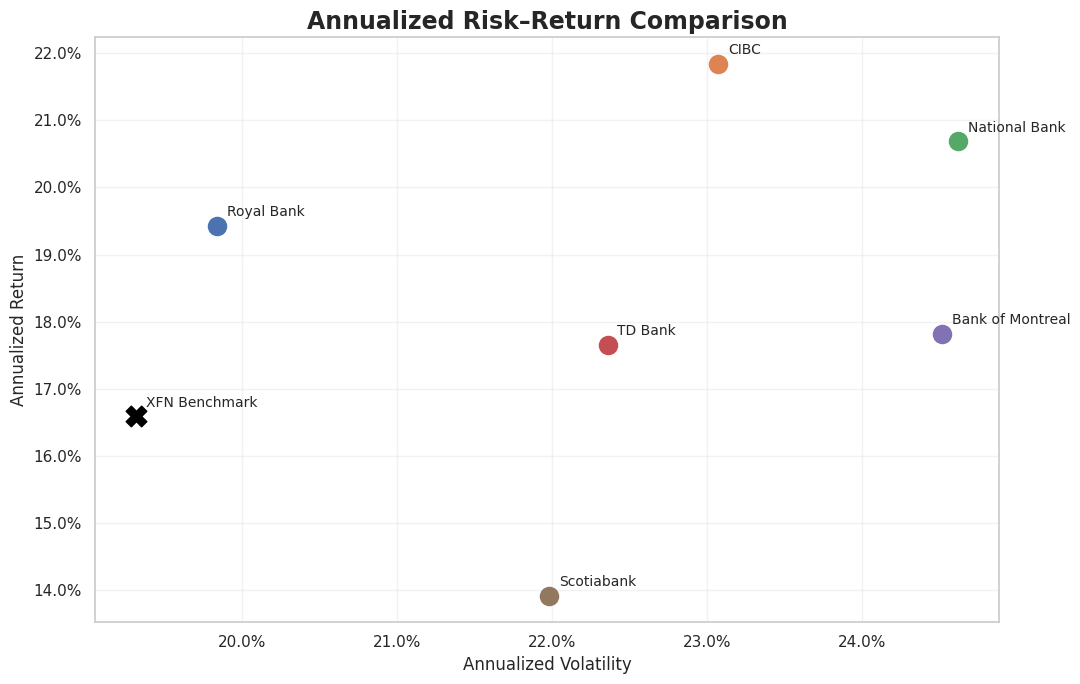

In [10]:
fig, ax = plt.subplots(figsize=(11, 7))

for asset in summary_metrics.index:
    x = summary_metrics.loc[asset, "Annualized Volatility"]
    y = summary_metrics.loc[asset, "Annualized Return"]

    if asset == "XFN Benchmark":
        ax.scatter(
            x, y,
            s=220,
            color="black",
            marker="X",
            label="XFN Benchmark"
        )
    else:
        ax.scatter(x, y, s=170)

    ax.annotate(
        asset,
        (x, y),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )

ax.set_title(
    "Annualized Risk–Return Comparison",
    fontsize=17,
    fontweight="bold"
)
ax.set_xlabel("Annualized Volatility")
ax.set_ylabel("Annualized Return")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("risk_return_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

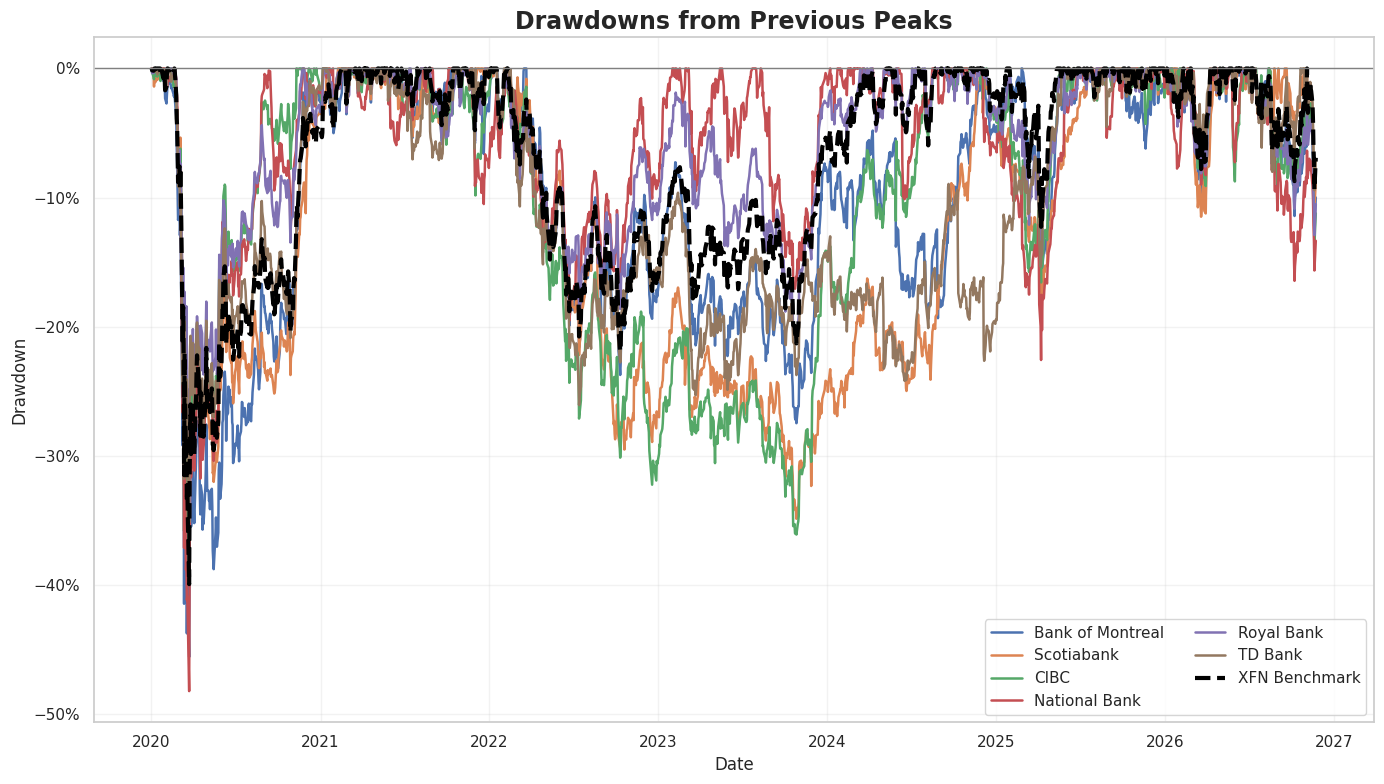

In [11]:
fig, ax = plt.subplots(figsize=(14, 8))

for asset in drawdowns.columns:
    if asset == "XFN Benchmark":
        ax.plot(
            drawdowns.index,
            drawdowns[asset],
            label=asset,
            color="black",
            linewidth=3,
            linestyle="--"
        )
    else:
        ax.plot(
            drawdowns.index,
            drawdowns[asset],
            label=asset,
            linewidth=1.8
        )

ax.axhline(0, color="gray", linewidth=1)
ax.set_title(
    "Drawdowns from Previous Peaks",
    fontsize=17,
    fontweight="bold"
)
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(ncol=2, frameon=True)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("drawdown_history.png", dpi=300, bbox_inches="tight")
plt.show()

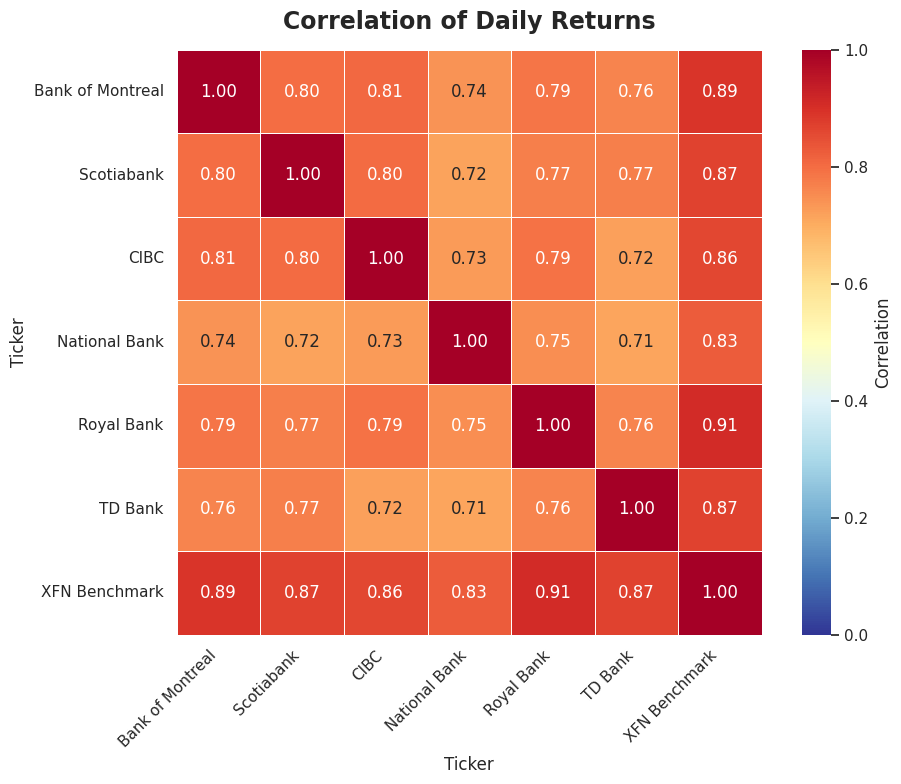

In [12]:
correlation_matrix = daily_returns.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"}
)

plt.title(
    "Correlation of Daily Returns",
    fontsize=17,
    fontweight="bold",
    pad=15
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("return_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
monthly_prices = prices.resample("ME").last()
monthly_returns = monthly_prices.pct_change().dropna()

monthly_summary = pd.DataFrame({
    "Best Monthly Return": monthly_returns.max(),
    "Best Month": monthly_returns.idxmax().dt.strftime("%Y-%m"),
    "Worst Monthly Return": monthly_returns.min(),
    "Worst Month": monthly_returns.idxmin().dt.strftime("%Y-%m"),
    "Average Monthly Return": monthly_returns.mean()
})

display(
    monthly_summary.style.format({
        "Best Monthly Return": "{:.1%}",
        "Worst Monthly Return": "{:.1%}",
        "Average Monthly Return": "{:.2%}"
    })
)

,Best Monthly Return,Best Month,Worst Monthly Return,Worst Month,Average Monthly Return
Ticker,,,,,
Bank of Montreal,17.7%,2023-12,-22.1%,2020-03,1.58%
Scotiabank,14.2%,2020-11,-18.2%,2020-03,1.28%
CIBC,15.3%,2023-12,-18.3%,2020-03,1.87%
National Bank,17.3%,2026-02,-21.0%,2020-03,1.76%
Royal Bank,13.8%,2020-11,-12.7%,2020-03,1.61%
TD Bank,17.9%,2020-11,-13.3%,2020-03,1.52%
XFN Benchmark,16.6%,2020-11,-18.6%,2020-03,1.40%


In [14]:
# Convert the analysis tables into database-friendly long format
prices_long = (
    prices.rename_axis("date")
    .reset_index()
    .melt(
        id_vars="date",
        var_name="asset",
        value_name="adjusted_close"
    )
)

returns_long = (
    daily_returns.rename_axis("date")
    .reset_index()
    .melt(
        id_vars="date",
        var_name="asset",
        value_name="daily_return"
    )
)

monthly_returns_long = (
    monthly_returns.rename_axis("date")
    .reset_index()
    .melt(
        id_vars="date",
        var_name="asset",
        value_name="monthly_return"
    )
)

summary_sql = (
    summary_metrics.rename_axis("asset")
    .reset_index()
)

# Store dates as text so they are easy to query in SQLite
prices_long["date"] = prices_long["date"].dt.strftime("%Y-%m-%d")
returns_long["date"] = returns_long["date"].dt.strftime("%Y-%m-%d")
monthly_returns_long["date"] = (
    monthly_returns_long["date"].dt.strftime("%Y-%m-%d")
)

# Create the SQLite database
connection = sqlite3.connect("canadian_bank_analysis.db")

prices_long.to_sql(
    "daily_prices", connection, if_exists="replace", index=False
)
returns_long.to_sql(
    "daily_returns", connection, if_exists="replace", index=False
)
monthly_returns_long.to_sql(
    "monthly_returns", connection, if_exists="replace", index=False
)
summary_sql.to_sql(
    "summary_metrics", connection, if_exists="replace", index=False
)

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    connection
)

display(tables)

,name
0,daily_prices
1,daily_returns
2,monthly_returns
3,summary_metrics


In [15]:
sql_queries = {
    "1. Risk-adjusted performance ranking": """
        SELECT
            asset,
            ROUND("Annualized Return" * 100, 2) AS annual_return_pct,
            ROUND("Annualized Volatility" * 100, 2) AS volatility_pct,
            ROUND("Sharpe Ratio", 2) AS sharpe_ratio
        FROM summary_metrics
        ORDER BY "Sharpe Ratio" DESC;
    """,

    "2. Banks that outperformed the XFN benchmark": """
        WITH benchmark AS (
            SELECT "Annualized Return" AS benchmark_return
            FROM summary_metrics
            WHERE asset = 'XFN Benchmark'
        )
        SELECT
            s.asset,
            ROUND(s."Annualized Return" * 100, 2) AS annual_return_pct,
            ROUND(
                (s."Annualized Return" - b.benchmark_return) * 100,
                2
            ) AS excess_return_pct
        FROM summary_metrics AS s
        CROSS JOIN benchmark AS b
        WHERE s.asset <> 'XFN Benchmark'
          AND s."Annualized Return" > b.benchmark_return
        ORDER BY excess_return_pct DESC;
    """,

    "3. Ten worst individual trading days": """
        SELECT
            date,
            asset,
            ROUND(daily_return * 100, 2) AS daily_return_pct
        FROM daily_returns
        WHERE asset <> 'XFN Benchmark'
        ORDER BY daily_return ASC
        LIMIT 10;
    """,

    "4. Best and worst month for each asset": """
        WITH ranked_months AS (
            SELECT
                asset,
                date,
                monthly_return,
                ROW_NUMBER() OVER (
                    PARTITION BY asset
                    ORDER BY monthly_return DESC
                ) AS best_rank,
                ROW_NUMBER() OVER (
                    PARTITION BY asset
                    ORDER BY monthly_return ASC
                ) AS worst_rank
            FROM monthly_returns
        )
        SELECT
            asset,
            MAX(
                CASE WHEN best_rank = 1 THEN date END
            ) AS best_month,
            ROUND(
                MAX(CASE WHEN best_rank = 1
                    THEN monthly_return END) * 100,
                2
            ) AS best_return_pct,
            MAX(
                CASE WHEN worst_rank = 1 THEN date END
            ) AS worst_month,
            ROUND(
                MIN(CASE WHEN worst_rank = 1
                    THEN monthly_return END) * 100,
                2
            ) AS worst_return_pct
        FROM ranked_months
        GROUP BY asset
        ORDER BY asset;
    """,

    "5. Percentage of positive trading days": """
        SELECT
            asset,
            COUNT(*) AS trading_days,
            SUM(
                CASE WHEN daily_return > 0 THEN 1 ELSE 0 END
            ) AS positive_days,
            ROUND(
                100.0 * AVG(
                    CASE WHEN daily_return > 0 THEN 1.0 ELSE 0.0 END
                ),
                2
            ) AS positive_day_pct
        FROM daily_returns
        GROUP BY asset
        ORDER BY positive_day_pct DESC;
    """
}

for title, query in sql_queries.items():
    print("\n" + title)
    display(pd.read_sql_query(query, connection))


1. Risk-adjusted performance ranking


,asset,annual_return_pct,volatility_pct,sharpe_ratio
0,Royal Bank,19.43,19.84,0.84
1,CIBC,21.84,23.07,0.84
2,National Bank,20.68,24.62,0.76
3,XFN Benchmark,16.59,19.32,0.74
4,TD Bank,17.66,22.36,0.70
5,Bank of Montreal,17.82,24.52,0.67
6,Scotiabank,13.92,21.98,0.57



2. Banks that outperformed the XFN benchmark


,asset,annual_return_pct,excess_return_pct
0,CIBC,21.84,5.25
1,National Bank,20.68,4.09
2,Royal Bank,19.43,2.84
3,Bank of Montreal,17.82,1.23
4,TD Bank,17.66,1.07



3. Ten worst individual trading days


,date,asset,daily_return_pct
0,2020-03-12,CIBC,-17.13
1,2020-03-16,National Bank,-16.76
2,2020-03-12,Bank of Montreal,-16.41
3,2020-03-09,CIBC,-13.67
4,2020-03-12,Scotiabank,-13.37
5,2020-03-09,Bank of Montreal,-13.29
6,2020-03-12,National Bank,-12.53
7,2020-03-16,Bank of Montreal,-12.38
8,2020-03-09,TD Bank,-12.33
9,2020-03-09,National Bank,-11.94



4. Best and worst month for each asset


,asset,best_month,best_return_pct,worst_month,worst_return_pct
0,Bank of Montreal,2023-12-31,17.71,2020-03-31,-22.09
1,CIBC,2023-12-31,15.34,2020-03-31,-18.27
2,National Bank,2026-02-28,17.33,2020-03-31,-21.01
3,Royal Bank,2020-11-30,13.85,2020-03-31,-12.67
4,Scotiabank,2020-11-30,14.18,2020-03-31,-18.16
5,TD Bank,2020-11-30,17.86,2020-03-31,-13.34
6,XFN Benchmark,2020-11-30,16.60,2020-03-31,-18.63



5. Percentage of positive trading days


,asset,trading_days,positive_days,positive_day_pct
0,Royal Bank,1730,973,56.24
1,CIBC,1730,973,56.24
2,XFN Benchmark,1730,970,56.07
3,National Bank,1730,963,55.66
4,TD Bank,1730,955,55.20
5,Scotiabank,1730,944,54.57
6,Bank of Montreal,1730,939,54.28


## Executive Summary

This analysis compared Canada’s Big Six banks with the XFN Canadian financial-sector benchmark from January 2020 through November 2026.

CIBC generated the highest absolute performance, with a 288.1% cumulative return and a 21.8% annualized return. Royal Bank produced the strongest overall risk-return profile: its 0.84 Sharpe ratio matched CIBC’s, but it experienced lower annualized volatility and a smaller maximum drawdown.

National Bank also generated strong returns, but its 48.2% maximum drawdown was the deepest in the group. Scotiabank was the only bank that underperformed XFN on annualized return and Sharpe ratio.

All banks experienced their worst monthly return in March 2020. Daily-return correlations between the individual banks ranged from approximately 0.71 to 0.81, showing that holding multiple Canadian bank stocks provides limited protection against sector-wide shocks.

Overall, the analysis demonstrates that the highest-returning asset is not automatically the strongest choice after accounting for volatility and downside risk.

## Limitations

- Historical performance does not predict future returns.
- Yahoo Finance data may contain revisions or data-quality limitations.
- Adjusted prices account for distributions, but the analysis excludes taxes, transaction costs, and investor-specific constraints.
- The 3% risk-free rate is a simplifying assumption rather than a time-varying market rate.
- XFN is a financial-sector benchmark with substantial exposure to the same banks, not a broad-market index.
- The analysis focuses on market prices and does not include bank fundamentals, valuation ratios, credit quality, or macroeconomic forecasting.
- Results depend on the selected January 2020–November 2026 period.

## Conclusion

Royal Bank offered the most balanced historical risk-return profile in the selected period, while CIBC delivered the strongest absolute return. The results favour evaluating return, volatility, drawdown, and correlation together rather than ranking investments using return alone.

*This analysis is for educational purposes and is not investment advice.*

In [16]:
import os
import shutil
from google.colab import files

project_folder = "/content/canadian-bank-risk-analysis"

# Create professional project folders
os.makedirs(f"{project_folder}/data", exist_ok=True)
os.makedirs(f"{project_folder}/database", exist_ok=True)
os.makedirs(f"{project_folder}/figures", exist_ok=True)

# Export cleaned datasets
prices.rename_axis("Date").to_csv(
    f"{project_folder}/data/adjusted_prices.csv"
)
daily_returns.rename_axis("Date").to_csv(
    f"{project_folder}/data/daily_returns.csv"
)
monthly_returns.rename_axis("Date").to_csv(
    f"{project_folder}/data/monthly_returns.csv"
)
summary_metrics.rename_axis("Asset").to_csv(
    f"{project_folder}/data/summary_metrics.csv"
)

# Save the SQLite database
connection.close()
shutil.copy(
    "/content/canadian_bank_analysis.db",
    f"{project_folder}/database/canadian_bank_analysis.db"
)

# Copy the four charts
chart_files = [
    "cumulative_returns.png",
    "risk_return_scatter.png",
    "drawdown_history.png",
    "return_correlation_heatmap.png"
]

for chart in chart_files:
    shutil.copy(
        f"/content/{chart}",
        f"{project_folder}/figures/{chart}"
    )

# Create requirements file
requirements = """pandas
numpy
yfinance
matplotlib
seaborn
"""

with open(f"{project_folder}/requirements.txt", "w") as file:
    file.write(requirements)

# Create a polished GitHub README
readme = """# Canadian Bank Performance and Risk Analysis

A Python and SQL analysis comparing the historical performance, volatility, drawdowns, correlations, and risk-adjusted returns of Canada's Big Six banks against the XFN Canadian financial-sector benchmark.

## Business Question

How have Canada's largest publicly traded banks compared in historical return, volatility, downside risk, and risk-adjusted performance relative to a Canadian financial-sector benchmark?

## Assets Analyzed

- Royal Bank of Canada
- Toronto-Dominion Bank
- Bank of Montreal
- Bank of Nova Scotia
- Canadian Imperial Bank of Commerce
- National Bank of Canada
- XFN iShares S&P/TSX Capped Financials Index ETF

## Analysis Period

January 2020 through November 2026.

## Tools

Python, pandas, NumPy, yfinance, matplotlib, seaborn, SQLite, SQL, Google Colab, and GitHub.

## Methods

- Collected adjusted market-price data using yfinance
- Checked missing values, duplicate dates, and invalid prices
- Calculated daily, monthly, cumulative, and annualized returns
- Measured annualized volatility and maximum drawdown
- Calculated Sharpe ratios using an assumed 3% risk-free rate
- Compared each bank with the XFN benchmark
- Analyzed daily-return correlations
- Stored analysis tables in SQLite
- Wrote five SQL queries for performance ranking, benchmark comparison, extreme losses, monthly extremes, and positive-day frequency

## Key Findings

- CIBC generated the highest cumulative and annualized returns.
- Royal Bank displayed the strongest overall risk-return balance, matching CIBC's Sharpe ratio with lower volatility and a smaller drawdown.
- National Bank generated strong returns but experienced the deepest maximum drawdown.
- Scotiabank underperformed XFN on annualized return and risk-adjusted performance.
- March 2020 was the worst month for every asset in the analysis.
- High correlations among the banks indicate limited protection against sector-wide shocks.

## Visualizations

![Cumulative Returns](figures/cumulative_returns.png)

![Risk and Return](figures/risk_return_scatter.png)

![Drawdown History](figures/drawdown_history.png)

![Return Correlations](figures/return_correlation_heatmap.png)

## Repository Structure

- `Canadian_Bank_Performance_and_Risk_Analysis.ipynb` — complete analysis
- `data/` — cleaned prices, returns, and summary metrics
- `database/` — SQLite analysis database
- `figures/` — exported visualizations
- `requirements.txt` — required Python packages

## Limitations

Historical performance does not predict future returns. Results depend on the selected period and a fixed 3% risk-free-rate assumption. The analysis excludes taxes, transaction costs, valuation ratios, bank fundamentals, and macroeconomic forecasts. XFN contains substantial exposure to the analyzed banks and is not a broad-market benchmark.

## Author

**Shyla Khullar**
UBC Mathematics student pursuing a Statistics minor
[LinkedIn](https://www.linkedin.com/in/shyla-khullar-a6a205247)

*This project is for educational purposes and is not investment advice.*
"""

with open(f"{project_folder}/README.md", "w") as file:
    file.write(readme)

# Create and download one ZIP file
zip_path = shutil.make_archive(
    "/content/canadian-bank-risk-analysis",
    "zip",
    "/content",
    "canadian-bank-risk-analysis"
)

print("Project files created successfully.")
files.download(zip_path)

Project files created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>